# Three-period stability check

This approved follow-up compares **eight existing candidates** using the original192 observations only. It does not create a cross-product search of category weights and news/technical weights.

Candidates1-6 use the six approved news formulas at70% news /30% technical: original40/20/20/20, equal25/25/25/25, Bitcoin only, crypto only, Bitcoin80% and crypto80% (the remaining20% divided equally). Candidates7-8 use the original news formula at5% news /95% technical and95% news /5% technical. These last two mixes are included because they led the previously inspected earlier and later results, respectively. Candidate selection is retrospective; this is a historical consistency check, not independent validation.

Before execution, fix three expanding-history rounds: train on rows0-95 and evaluate96-123; train0-123 and evaluate124-152; train0-152 and evaluate153-191. These correspond to the first50%, then50-65%,65-80% and80-100%, with integer boundaries96,124,153,192. The **forty newer observations remain excluded**.

Each candidate independently selects a threshold using only preceding records. Grid0.05-0.55 in0.05 steps; at least10 completed training trades; highest training net return, tie by more trades then smaller threshold. No eligible threshold means an unavailable evaluation, not zero performance. Thresholds stay fixed within an evaluation period but can change before the next round.

Common rules: fixed24-hour hold, one position at a time, next hourly open after each signal, $1,000 starting equity in each segment,0.10% fee and0.05% slippage on each side. Buying-only and long/short are separate. Trades crossing a segment endpoint are excluded. No leverage, funding, borrowing, liquidation or stop-loss/take-profit model. Scores use the original scalar Python rounding convention. No new price data is fetched.


In [1]:
from pathlib import Path
import hashlib,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
%matplotlib inline
candidates=[Path.cwd(),Path.cwd()/"notebooks/category_research"]
HERE=next(p for p in candidates if (p/"audit_results/azure_matching_previous_192.csv").exists())
PROJECT=HERE.parents[1]
OUT=HERE/"sequential_stability_results"
OUT.mkdir(exist_ok=True)
INPUTS=[HERE/"audit_results/azure_matching_previous_192.csv",PROJECT/"notebooks/recent_data/btc_hourly_recent.csv",
        PROJECT/"notebooks/recent_data/signals_recent.csv"]
EXPECTED={'azure_matching_previous_192.csv': 'f5fc7adaf15528c7bac8bb2c5a76be729cf55930e299f00772dd8584ed83500e', 'btc_hourly_recent.csv': '8b362387fe685c09c2da4149547f867b5eb3a905452a88cbafad65a210b53551', 'signals_recent.csv': 'b3a15d9f7375e01f24b5f1b18db8109c80102db425b47264925cead502db2e17'}
for p in INPUTS:assert hashlib.sha256(p.read_bytes()).hexdigest()==EXPECTED[p.name]
signals=pd.read_csv(INPUTS[0]);old=pd.read_csv(INPUTS[2])
for frame in [signals,old]:
    frame["timestamp"]=pd.to_datetime(frame.timestamp,format="mixed",utc=True)
    frame.sort_values("timestamp",inplace=True);frame.reset_index(drop=True,inplace=True)
assert len(signals)==len(old)==192
assert signals.timestamp.dt.floor("ms").equals(old.timestamp)
assert signals.symbol.equals(old.symbol)
market=pd.read_csv(INPUTS[1]);market["open_time"]=pd.to_datetime(market.open_time,utc=True)
P=market.set_index("open_time").open
assert P.index.is_unique and P.index.is_monotonic_increasing
assert P.index.to_series().diff().dropna().eq(pd.Timedelta(hours=1)).all()
signals["entry_time"]=signals.timestamp.dt.floor("h")+pd.Timedelta(hours=1)
CATEGORY_COLUMNS=["bitcoin_score","crypto_score","politics_score","war_macro_score"]
FORMULAS={"Original70/30":((.4,.2,.2,.2),.7),"Equal70/30":((.25,.25,.25,.25),.7),
          "Bitcoin-only70/30":((1.,0.,0.,0.),.7),"Crypto-only70/30":((0.,1.,0.,0.),.7),
          "Bitcoin80%70/30":((.8,.2/3,.2/3,.2/3),.7),"Crypto80%70/30":((.2/3,.8,.2/3,.2/3),.7),
          "Original5/95":((.4,.2,.2,.2),.05),"Original95/5":((.4,.2,.2,.2),.95)}
SCORE_COLUMNS={};candidate_rows=[]
for i,(name,(weights,news_weight)) in enumerate(FORMULAS.items()):
    news_col=f"candidate_news_{i}";p_col=f"candidate_p_{i}"
    signals[news_col]=signals.apply(lambda r:round(sum(float(r[c])*w for c,w in zip(CATEGORY_COLUMNS,weights)),4),axis=1)
    # Preserve the exact previously tested coefficient representation:0.95/0.05,0.05/0.95,0.7/0.3.
    ta_weight={.7:.3,.05:.95,.95:.05}[news_weight]
    signals[p_col]=signals.apply(lambda r:max(-1.,min(1.,round(float(r[news_col])*news_weight+float(r.ta_score)*ta_weight,4))),axis=1)
    SCORE_COLUMNS[name]=p_col
    candidate_rows.append(dict(candidate=name,score_column=p_col,news_weight=news_weight,technical_weight=ta_weight,
                                **dict(zip(CATEGORY_COLUMNS,weights))))
assert np.allclose(signals.candidate_news_0,signals.news_score,atol=1e-10,rtol=0)
assert np.allclose(signals.candidate_p_0,signals.p_score,atol=1e-10,rtol=0)
candidate_table=pd.DataFrame(candidate_rows)
candidate_table.to_csv(OUT/"fixed_candidates.csv",index=False)
display(candidate_table)
plt.rcParams.update({"font.size":10,"axes.spines.top":False,"axes.spines.right":False})


,candidate,score_column,news_weight,technical_weight,bitcoin_score,crypto_score,politics_score,war_macro_score
0,Original70/30,candidate_p_0,0.70,0.30,0.400000,0.200000,0.200000,0.200000
1,Equal70/30,candidate_p_1,0.70,0.30,0.250000,0.250000,0.250000,0.250000
2,Bitcoin-only70/30,candidate_p_2,0.70,0.30,1.000000,0.000000,0.000000,0.000000
3,Crypto-only70/30,candidate_p_3,0.70,0.30,0.000000,1.000000,0.000000,0.000000
4,Bitcoin80%70/30,candidate_p_4,0.70,0.30,0.800000,0.066667,0.066667,0.066667
5,Crypto80%70/30,candidate_p_5,0.70,0.30,0.066667,0.800000,0.066667,0.066667
6,Original5/95,candidate_p_6,0.05,0.95,0.400000,0.200000,0.200000,0.200000
7,Original95/5,candidate_p_7,0.95,0.05,0.400000,0.200000,0.200000,0.200000


In [2]:
THRESHOLD_GRID=[round(x,2) for x in np.arange(.05,.551,.05)]
HOLD_GRID=[1,4,8,12,24,48]
MODES=["Buying only","Long and short"]
STARTING_EQUITY=1000.
FEE_RATE=.001
SLIPPAGE_RATE=.0005
MIN_TRAINING_TRADES=10
RECENT_N=len(signals)
RECENT_CUT=int(RECENT_N*.7)
RECENT_SPLIT=signals.timestamp.iloc[RECENT_CUT]
RECENT_END=P.index.max()
SEGMENTS=[("Earlier",0,RECENT_CUT),("Later",RECENT_CUT,RECENT_N),("Full recent sample",0,RECENT_N)]
PRICE_LOOKUP=P.to_dict()
SIMULATIONS={}
TRADE_COLS=["source_row","signal_time","entry_time","exit_time","side","p_score","entry_open","exit_open",
            "entry_fill","exit_fill","quantity","initial_equity","ending_equity","net_pnl","net_return","fees","signal_score","score_column"]

def simulate_recent_score(score_column,threshold,holding_hours,mode,begin,end):
    key=(score_column,threshold,holding_hours,mode,begin,end)
    if key in SIMULATIONS:
        return SIMULATIONS[key]
    start=signals.entry_time.iloc[begin]
    finish=RECENT_END if end==RECENT_N else signals.timestamp.iloc[end].floor("h")
    capital=STARTING_EQUITY
    next_free=start
    trades=[]
    curve=pd.Series(np.nan,index=P.loc[start:finish].index,dtype=float)
    curve.iloc[0]=capital
    for i in range(begin,end):
        row=signals.iloc[i]
        signal_score=float(row[score_column])
        side=1 if signal_score>=threshold else (-1 if mode=="Long and short" and signal_score<=-threshold else 0)
        if not side:
            continue
        entry=row.entry_time
        exit_time=entry+pd.Timedelta(hours=holding_hours)
        if entry<start or entry<next_free or exit_time>finish or entry not in PRICE_LOOKUP or exit_time not in PRICE_LOOKUP:
            continue
        entry_mid=float(PRICE_LOOKUP[entry]);exit_mid=float(PRICE_LOOKUP[exit_time])
        entry_fill=entry_mid*(1+side*SLIPPAGE_RATE)
        exit_fill=exit_mid*(1-side*SLIPPAGE_RATE)
        quantity=capital/(entry_fill*(1+FEE_RATE))
        fee_in=quantity*entry_fill*FEE_RATE
        fee_out=quantity*exit_fill*FEE_RATE
        final=capital-fee_in+side*quantity*(exit_fill-entry_fill)-fee_out
        assert final>0,"Equity exhausted; liquidation is not implemented in this model."
        marks=P.loc[entry:exit_time].iloc[:-1]
        curve.loc[marks.index]=capital-fee_in+side*quantity*(marks-entry_fill)
        curve.loc[exit_time]=final
        trades.append(dict(source_row=i,signal_time=row.timestamp,entry_time=entry,exit_time=exit_time,
            side=side,p_score=row.p_score,signal_score=signal_score,score_column=score_column,entry_open=entry_mid,exit_open=exit_mid,entry_fill=entry_fill,
            exit_fill=exit_fill,quantity=quantity,initial_equity=capital,ending_equity=final,
            net_pnl=final-capital,net_return=final/capital-1,fees=fee_in+fee_out))
        capital=final
        next_free=exit_time
    curve=curve.ffill()
    values=np.r_[STARTING_EQUITY,curve.to_numpy()]
    max_dd=float(np.min(values/np.maximum.accumulate(values)-1)*100)
    table=pd.DataFrame(trades,columns=TRADE_COLS)
    gross_profit=sum(max(t["net_pnl"],0) for t in trades)
    gross_loss=-sum(min(t["net_pnl"],0) for t in trades)
    metrics=dict(score_column=score_column,mode=mode,threshold=threshold,holding_hours=holding_hours,trades=len(table),
        longs=sum(t["side"]==1 for t in trades),shorts=sum(t["side"]==-1 for t in trades),
        return_pct=(capital/STARTING_EQUITY-1)*100,final_equity=capital,hourly_max_drawdown_pct=max_dd,
        win_rate_pct=sum(t["net_pnl"]>0 for t in trades)/len(trades)*100 if trades else np.nan,
        profit_factor=gross_profit/gross_loss if gross_loss else np.nan,
        total_fees=sum(t["fees"] for t in trades),start_time=str(start),end_time=str(finish))
    run={"metrics":metrics,"trades":table,"equity":curve}
    SIMULATIONS[key]=run
    return run

def simulate_recent_p(threshold,holding_hours,mode,begin,end):
    return simulate_recent_score("p_score",threshold,holding_hours,mode,begin,end)


FOLDS=[("Round1",96,124),("Round2",124,153),("Round3",153,192)]
fold_rows=[]
for name,begin,end in FOLDS:
    fold_rows.append(dict(round=name,training_records=begin,evaluation_records=end-begin,
        training_first_score=str(signals.timestamp.iloc[0]),training_last_score=str(signals.timestamp.iloc[begin-1]),
        evaluation_first_score=str(signals.timestamp.iloc[begin]),evaluation_last_score=str(signals.timestamp.iloc[end-1]),
        training_end_hourly_open=str(signals.timestamp.iloc[begin].floor("h")),
        evaluation_start_hourly_open=str(signals.entry_time.iloc[begin]),
        evaluation_end_hourly_open=str(RECENT_END if end==192 else signals.timestamp.iloc[end].floor("h"))))
folds=pd.DataFrame(fold_rows)
display(folds)
folds.to_csv(OUT/"fixed_time_splits.csv",index=False)


,round,training_records,evaluation_records,training_first_score,training_last_score,evaluation_first_score,evaluation_last_score,training_end_hourly_open,evaluation_start_hourly_open,evaluation_end_hourly_open
0,Round1,96,28,2026-09-24 20:51:46.882448+00:00,2026-10-13 10:51:09.176581+00:00,2026-10-13 14:50:46.228937+00:00,2026-10-20 06:49:03.791493+00:00,2026-10-13 14:00:00+00:00,2026-10-13 15:00:00+00:00,2026-10-20 10:00:00+00:00
1,Round2,124,29,2026-09-24 20:51:46.882448+00:00,2026-10-20 06:49:03.791493+00:00,2026-10-20 10:48:25.366001+00:00,2026-10-25 02:48:14.584621+00:00,2026-10-20 10:00:00+00:00,2026-10-20 11:00:00+00:00,2026-10-25 06:00:00+00:00
2,Round3,153,39,2026-09-24 20:51:46.882448+00:00,2026-10-25 02:48:14.584621+00:00,2026-10-25 06:48:04.588514+00:00,2026-10-31 14:49:26.863784+00:00,2026-10-25 06:00:00+00:00,2026-10-25 07:00:00+00:00,2026-10-31 14:00:00+00:00


## Training-only threshold selection

For each round, generate only the training grid and choose a setting per candidate and mode. The entire selection table is fixed before evaluation results are computed. Even a negative training winner remains a negative result; this study does not introduce a new rule to stop trading after negative training performance.


In [3]:
grid_rows=[];choice_rows=[]
for fold,begin,end in FOLDS:
    for candidate,column in SCORE_COLUMNS.items():
        for mode in MODES:
            available=[]
            for threshold in THRESHOLD_GRID:
                run=simulate_recent_score(column,threshold,24,mode,0,begin)
                row=dict(round=fold,candidate=candidate,**run["metrics"])
                grid_rows.append(row)
                if row["trades"]>=10:available.append(row)
            if not available:
                choice_rows.append(dict(round=fold,candidate=candidate,mode=mode,status="No eligible training threshold",
                    threshold=np.nan,training_return_pct=np.nan,training_trades=np.nan))
                continue
            best=sorted(available,key=lambda r:(-r["return_pct"],-r["trades"],r["threshold"]))[0]
            choice_rows.append(dict(round=fold,candidate=candidate,mode=mode,status="Eligible",threshold=best["threshold"],
                    training_return_pct=best["return_pct"],training_trades=best["trades"]))
grid=pd.DataFrame(grid_rows);choices=pd.DataFrame(choice_rows)
assert len(grid)==3*8*2*11 and len(choices)==3*8*2
grid.to_csv(OUT/"training_threshold_grids.csv",index=False)
choices.to_csv(OUT/"training_selected_thresholds.csv",index=False)
display(choices.round(4))


,round,candidate,mode,status,threshold,training_return_pct,training_trades
0,Round1,Original70/30,Buying only,No eligible training threshold,NaN,NaN,NaN
1,Round1,Original70/30,Long and short,Eligible,0.20,2.4754,10.0
2,Round1,Equal70/30,Buying only,No eligible training threshold,NaN,NaN,NaN
3,Round1,Equal70/30,Long and short,Eligible,0.15,-2.6507,12.0
4,Round1,Bitcoin-only70/30,Buying only,Eligible,0.25,-2.8032,10.0
5,Round1,Bitcoin-only70/30,Long and short,Eligible,0.30,2.4969,11.0
6,Round1,Crypto-only70/30,Buying only,Eligible,0.05,-4.8859,11.0
7,Round1,Crypto-only70/30,Long and short,Eligible,0.20,-7.8094,12.0
8,Round1,Bitcoin80%70/30,Buying only,Eligible,0.05,-2.9323,13.0
9,Round1,Bitcoin80%70/30,Long and short,Eligible,0.25,1.9123,10.0


## Evaluation with frozen thresholds

Each evaluation restarts at $1,000. Do not add or compound the three returns into a continuously traded account: segment boundaries censor trades and change availability. Compare period results and trade counts directly. Newer observations are not loaded by this notebook.


In [4]:
result_rows=[]
for choice in choices.itertuples():
    if choice.status!="Eligible":continue
    _,begin,end=next(f for f in FOLDS if f[0]==choice.round)
    run=simulate_recent_score(SCORE_COLUMNS[choice.candidate],choice.threshold,24,choice.mode,begin,end)
    result_rows.append(dict(round=choice.round,candidate=choice.candidate,**run["metrics"]))
    slug=str(list(FORMULAS).index(choice.candidate))+"_"+choice.mode.lower().replace(" ","_")+"_"+choice.round.lower()
    run["trades"].to_csv(OUT/(slug+"_trades.csv"),index=False)
    run["equity"].rename("equity").rename_axis("timestamp").to_csv(OUT/(slug+"_equity.csv"))
results=pd.DataFrame(result_rows)
evaluation=choices.merge(results[["round","candidate","mode","return_pct","trades","hourly_max_drawdown_pct","final_equity"]],
                        on=["round","candidate","mode"],how="left",validate="one_to_one")
evaluation.to_csv(OUT/"round_evaluation_results.csv",index=False)
summary_rows=[]
for candidate in FORMULAS:
    for mode in MODES:
        part=evaluation.loc[evaluation.candidate.eq(candidate)&evaluation["mode"].eq(mode)]
        valid=part.loc[part.status.eq("Eligible")]
        row=dict(candidate=candidate,mode=mode,eligible_periods=len(valid),positive_periods=int(valid.return_pct.gt(0).sum()),
                 zero_trade_periods=int(valid.trades.eq(0).sum()),total_evaluation_trades=int(valid.trades.sum()),
                 worst_period_return_pct=valid.return_pct.min(),best_period_return_pct=valid.return_pct.max(),
                 worst_within_period_drawdown_pct=valid.hourly_max_drawdown_pct.min())
        for fold,_,_ in FOLDS:
            r=part.loc[part["round"].eq(fold)].iloc[0]
            row[fold+"_return_pct"]=r.return_pct;row[fold+"_trades"]=r.trades;row[fold+"_threshold"]=r.threshold
        summary_rows.append(row)
summary=pd.DataFrame(summary_rows)
summary.to_csv(OUT/"three_period_stability_summary.csv",index=False)
for mode in MODES:
    display(Markdown("### "+mode))
    display(summary.loc[summary["mode"].eq(mode)].drop(columns="mode").round(3))


### Buying only

,candidate,eligible_periods,positive_periods,zero_trade_periods,total_evaluation_trades,worst_period_return_pct,best_period_return_pct,worst_within_period_drawdown_pct,Round1_return_pct,Round1_trades,Round1_threshold,Round2_return_pct,Round2_trades,Round2_threshold,Round3_return_pct,Round3_trades,Round3_threshold
0,Original70/30,2,0,0,4,-2.254,-0.872,-5.599,NaN,NaN,NaN,-2.254,3.0,0.05,-0.872,1.0,0.05
2,Equal70/30,1,0,0,1,-0.872,-0.872,-1.227,NaN,NaN,NaN,NaN,NaN,NaN,-0.872,1.0,0.05
4,Bitcoin-only70/30,3,0,1,3,-2.750,0.000,-3.976,-2.033,1.0,0.25,-2.750,2.0,0.30,0.000,0.0,0.35
6,Crypto-only70/30,3,0,0,6,-2.254,-0.694,-5.599,-2.033,1.0,0.05,-2.254,3.0,0.05,-0.694,2.0,0.05
8,Bitcoin80%70/30,3,0,1,5,-2.033,0.000,-5.924,-2.033,1.0,0.05,-1.395,4.0,0.05,0.000,0.0,0.25
10,Crypto80%70/30,3,0,0,5,-2.254,-0.872,-5.599,-2.033,1.0,0.05,-2.254,3.0,0.05,-0.872,1.0,0.05
12,Original5/95,3,0,0,11,-4.143,-1.084,-6.538,-1.084,3.0,0.05,-1.323,3.0,0.15,-4.143,5.0,0.15
14,Original95/5,3,0,1,3,-2.679,0.000,-4.281,-2.033,1.0,0.05,-2.679,2.0,0.05,0.000,0.0,0.20


### Long and short

,candidate,eligible_periods,positive_periods,zero_trade_periods,total_evaluation_trades,worst_period_return_pct,best_period_return_pct,worst_within_period_drawdown_pct,Round1_return_pct,Round1_trades,Round1_threshold,Round2_return_pct,Round2_trades,Round2_threshold,Round3_return_pct,Round3_trades,Round3_threshold
1,Original70/30,3,2,0,7,-2.207,4.120,-3.633,-2.207,3.0,0.20,0.895,1.0,0.25,4.120,3.0,0.25
3,Equal70/30,3,3,0,10,0.895,3.693,-3.395,0.898,5.0,0.15,0.895,1.0,0.20,3.693,4.0,0.20
5,Bitcoin-only70/30,3,0,0,7,-2.932,-0.120,-4.100,-2.932,2.0,0.30,-1.963,3.0,0.30,-0.120,2.0,0.35
7,Crypto-only70/30,3,2,0,7,-1.894,6.001,-4.247,-1.894,3.0,0.20,1.047,1.0,0.30,6.001,3.0,0.30
9,Bitcoin80%70/30,3,0,0,9,-1.756,-0.120,-4.542,-1.756,4.0,0.25,-1.273,3.0,0.30,-0.120,2.0,0.30
11,Crypto80%70/30,3,2,0,8,-1.894,4.035,-4.247,-1.894,3.0,0.20,0.895,1.0,0.25,4.035,4.0,0.25
13,Original5/95,3,1,0,9,-3.611,0.262,-4.502,-2.921,3.0,0.10,0.262,4.0,0.35,-3.611,2.0,0.35
15,Original95/5,3,2,0,9,-1.602,4.282,-3.250,-1.602,3.0,0.30,0.687,2.0,0.30,4.282,4.0,0.30


## Verification

Independently check each threshold selection against its training grid; verify completed training trades finish before evaluation entry; reconcile selected evaluation trade costs and equity from hourly prices; verify no overlap, fixed24-hour exits, side rules, row boundaries and hourly drawdowns. The three evaluation periods contain mutually disjoint source-row ranges.


In [5]:
assert [end-begin for _,begin,end in FOLDS]==[28,29,39]
assert FOLDS[0][2]==FOLDS[1][1] and FOLDS[1][2]==FOLDS[2][1]
for choice in choices.itertuples():
    _,begin,end=next(f for f in FOLDS if f[0]==choice.round)
    eligible=grid.loc[grid["round"].eq(choice.round)&grid.candidate.eq(choice.candidate)&grid["mode"].eq(choice.mode)&grid.trades.ge(10)]
    if choice.status!="Eligible":assert eligible.empty;continue
    best=eligible.sort_values(["return_pct","trades","threshold"],ascending=[False,False,True],kind="stable").iloc[0]
    assert choice.threshold==best.threshold
    assert np.isclose(choice.training_return_pct,best.return_pct,atol=1e-12,rtol=0)
    train=simulate_recent_score(SCORE_COLUMNS[choice.candidate],choice.threshold,24,choice.mode,0,begin)
    assert train["trades"].exit_time.max()<=signals.timestamp.iloc[begin].floor("h")
    run=simulate_recent_score(SCORE_COLUMNS[choice.candidate],choice.threshold,24,choice.mode,begin,end)
    capital=1000.;last_exit=None
    finish=RECENT_END if end==192 else signals.timestamp.iloc[end].floor("h")
    for t in run["trades"].itertuples():
        assert begin<=t.source_row<end
        assert t.entry_time>t.signal_time and t.exit_time-t.entry_time==pd.Timedelta(hours=24)
        assert t.exit_time<=finish
        assert last_exit is None or t.entry_time>=last_exit
        assert t.side==(1 if t.signal_score>=choice.threshold else -1)
        assert abs(t.signal_score)>=choice.threshold
        if choice.mode=="Buying only":assert t.side==1
        ef=float(P.loc[t.entry_time])*(1+t.side*.0005)
        xf=float(P.loc[t.exit_time])*(1-t.side*.0005)
        qty=capital/(ef*1.001)
        capital+=t.side*qty*(xf-ef)-qty*(ef+xf)*.001
        assert np.isclose(capital,t.ending_equity,atol=1e-9,rtol=0)
        last_exit=t.exit_time
    assert np.isclose(capital,run["metrics"]["final_equity"],atol=1e-9,rtol=0)
    values=np.r_[1000.,run["equity"].to_numpy()]
    dd=(values/np.maximum.accumulate(values)-1).min()*100
    assert np.isclose(dd,run["metrics"]["hourly_max_drawdown_pct"],atol=1e-10,rtol=0)
checks=pd.DataFrame({"check":["Input hashes and original192 matching sample verified","Training-only optimal eligible thresholds verified",
    "Training exits precede evaluation entry","Three nonoverlapping evaluation source-row ranges verified",
    "Evaluation trade timing/side/hold/no overlap verified","Independent fee/slippage/equity accounting verified",
    "Hourly drawdowns verified"],"passed":True})
display(checks);checks.to_csv(OUT/"stability_checks.csv",index=False)


,check,passed
0,Input hashes and original192 matching sample v...,True
1,Training-only optimal eligible thresholds veri...,True
2,Training exits precede evaluation entry,True
3,Three nonoverlapping evaluation source-row ran...,True
4,Evaluation trade timing/side/hold/no overlap v...,True
5,Independent fee/slippage/equity accounting ver...,True
6,Hourly drawdowns verified,True


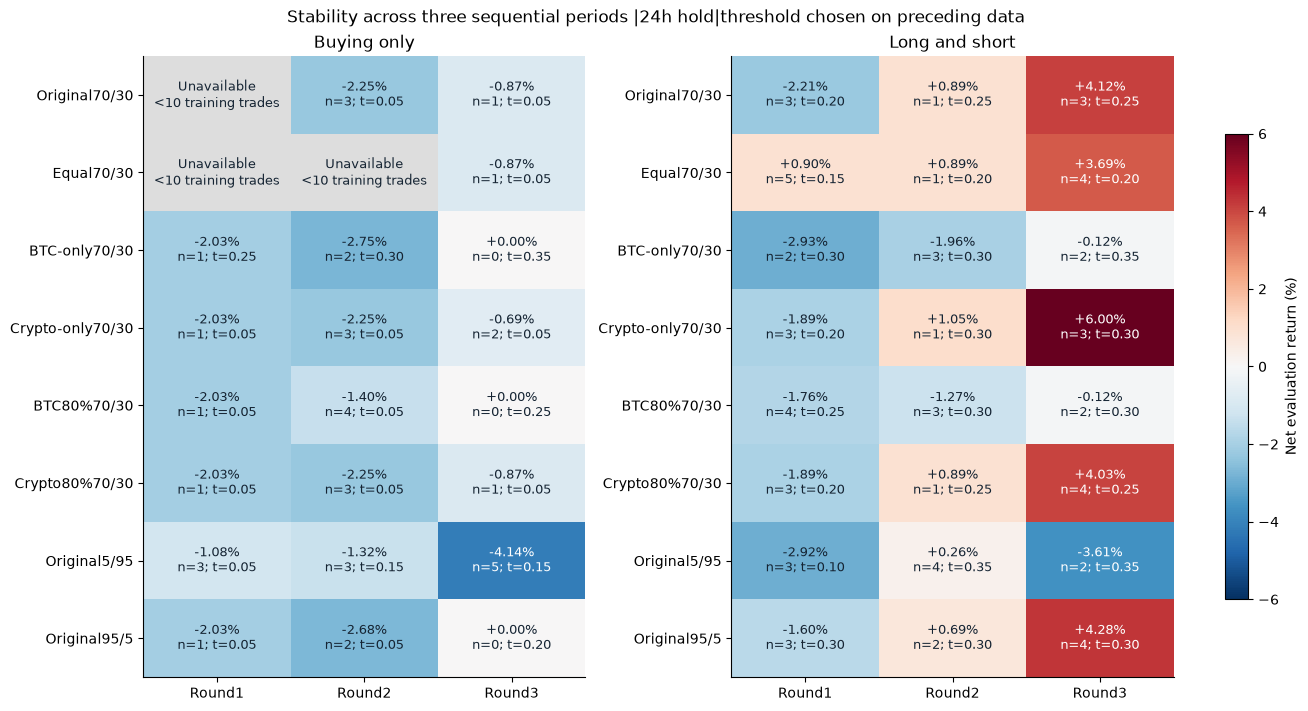

In [6]:
names=list(FORMULAS)
labels=["Original70/30","Equal70/30","BTC-only70/30","Crypto-only70/30","BTC80%70/30","Crypto80%70/30","Original5/95","Original95/5"]
valid_values=evaluation.return_pct.dropna()
limit=max(1,float(valid_values.abs().max()))
fig,axes=plt.subplots(1,2,figsize=(13,7),layout="constrained")
for ax,mode in zip(axes,MODES):
    a=evaluation.loc[evaluation["mode"].eq(mode)].pivot(index="candidate",columns="round",values="return_pct").reindex(names)
    cmap=plt.get_cmap("RdBu_r").copy();cmap.set_bad("#dddddd")
    im=ax.imshow(a.to_numpy(),cmap=cmap,vmin=-limit,vmax=limit,aspect="auto")
    ax.set_yticks(range(8),labels);ax.set_xticks(range(3),["Round1","Round2","Round3"])
    ax.set_title(mode)
    for i,name in enumerate(names):
        for j,fold in enumerate(a.columns):
            r=evaluation.loc[evaluation["mode"].eq(mode)&evaluation.candidate.eq(name)&evaluation["round"].eq(fold)].iloc[0]
            if r.status!="Eligible":text="Unavailable\n<10 training trades"
            else:text=f"{r.return_pct:+.2f}%\nn={int(r.trades)}; t={r.threshold:.2f}"
            color="white" if pd.notna(r.return_pct) and abs(r.return_pct)>limit*.6 else "#152433"
            ax.text(j,i,text,ha="center",va="center",fontsize=9,color=color)
fig.colorbar(im,ax=axes,label="Net evaluation return (%)",shrink=.75)
fig.suptitle("Stability across three sequential periods |24h hold|threshold chosen on preceding data")
fig.savefig(OUT/"three_period_returns.png",dpi=150,bbox_inches="tight",facecolor="white")
display(fig);plt.close(fig)


## Limits and approval boundary

The first round has fewer training observations, so some settings cannot meet the unchanged10-trade minimum. That is a limitation of available data, not a reason to relax eligibility after seeing results. Round trade counts are small, candidate definitions were chosen after earlier exploration, and every period has already been explored in other studies. Three periods from the same short history cannot establish future profitability.

No aggregate winning formula or adaptive selection rule is fitted here. No newer40 performance, extra candidate combinations, new thresholds, different holds or additional stress tests are included. Further work requires separate approval.


In [7]:
report={"scope":"Approved sequential consistency study","observations":192,"newer40_evaluated":False,
    "candidates":candidate_table.to_dict("records"),"folds":folds.to_dict("records"),
    "summary":json.loads(summary.to_json(orient="records")),"input_sha256":EXPECTED,
    "limitation":"Retrospective candidate selection;previously explored periods;small trade counts;unavailable settings preserved"}
(OUT/"stability_results.json").write_text(json.dumps(report,indent=2),encoding="utf-8")


14945

## Findings

Among the eight candidates, equal category weights at70/30 were the only long/short candidate positive in all three evaluation periods: +0.90%, +0.89% and +3.69%. They made5,1 and4 trades respectively, with selected thresholds0.15,0.20 and0.20. Their worst within-period hourly drawdown was -3.39%. This is a consistency observation over ten evaluation trades, not proof of an optimal formula.

The original40/20/20/20 formula at70/30 returned -2.21%, +0.89% and +4.12%, using3,1 and3 trades. Bitcoin only and Bitcoin80% at70/30 were negative in all three periods. Crypto only was negative in the first period and positive in the next two (-1.89%, +1.05%, +6.00%), so its attractive final result did not persist across every period.

Original news at5/95 was negative in two periods (-2.92%, +0.26%, -3.61%). Original news at95/5 was positive in two (-1.60%, +0.69%, +4.28%). No buying-only candidate had a positive evaluation period. Some buying-only candidates lacked an eligible training threshold in the early rounds; three last-round buying-only evaluations had zero trades and zero return.

The evidence favors further checking of balanced category weights over claiming that Bitcoin-heavy weights or the earlier5/95 winner are consistently better. Selecting equal weights after this comparison remains a retrospective choice. Any newer-sample evaluation must have its selection and threshold rules frozen beforehand. The newer40 records have not been evaluated.
